# Huấn luyện và đánh giá mô hình gợi ý cây trồng

Notebook tổng hợp so sánh đặc trưng, kết quả tuning của năm mô hình, đánh giá cuối và phân tích lỗi.
Các bảng tuning và test được đọc từ kết quả thực nghiệm trong repository. Phép so sánh đặc trưng được chạy lại trên train/validation, còn pipeline tốt nhất được nạp từ tệp dùng chung với demo.

Đầu vào gồm N, P, K, temperature, humidity, ph và rainfall. Đầu ra là một trong 22 loại cây.


## 1. Môi trường và dữ liệu

Chạy notebook từ thư mục gốc dự án hoặc thư mục notebooks sau khi cài requirements.txt.
Cần có dữ liệu đã chia, CSV kết quả và mô hình đã xuất. Các lệnh tái tạo ở cuối notebook.


In [1]:
from pathlib import Path
import json
import sys
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown, Image
pd.set_option("display.max_columns", None)

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(path for path in candidates if (path / "src" / "config.py").is_file())
sys.path.insert(0, str(ROOT / "src"))

from config import FEATURES, PROCESSED_DATA_DIR, BEST_MODEL_PATH
from evaluate_features import fit_feature_variants
from train_qda import load_training_data
from model_artifact import load_best_model
from compare_models import compute_metrics
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__)
print("pandas", pd.__version__, "| NumPy", np.__version__)
X_train, X_val, y_train, y_val = load_training_data()
X_test = pd.read_csv(PROCESSED_DATA_DIR / "X_test.csv")[FEATURES]
y_test = pd.read_csv(PROCESSED_DATA_DIR / "y_test.csv")["label"]
display(pd.DataFrame({
    "Tập": ["Train", "Validation", "Test"],
    "Số mẫu": [len(y_train), len(y_val), len(y_test)],
    "Số lớp": [y_train.nunique(), y_val.nunique(), y_test.nunique()],
}))


Python 3.12.14 | scikit-learn 1.9.1
pandas 3.1.1 | NumPy 2.5.5


,Tập,Số mẫu,Số lớp
0,Train,1540,22
1,Validation,330,22
2,Test,330,22


Train có 1.540 mẫu, validation có 330 mẫu và test có 330 mẫu. So sánh đặc trưng dùng train để fit và validation để đo điểm. Tuning gộp train và validation thành 1.870 mẫu phát triển.

Tập test được dùng để đánh giá sau khi chốt cấu hình CV. Nhóm đã quan sát kết quả test ở các lượt thử trước, nên cần trình bày lịch sử thực nghiệm này khi báo cáo. Điểm CV dùng để chọn mô hình được lấy từ cùng quá trình tìm siêu tham số.


## 2. So sánh trước và sau kỹ nghệ đặc trưng

Bộ đặc trưng mới gồm total_npk = N + P + K, np_ratio = N/P, nk_ratio = N/K và ph_distance_7 = |pH − 7|.
QDA bỏ total_npk do phụ thuộc tuyến tính với các cột gốc. Tỷ lệ có mẫu số bằng 0 được để thiếu rồi điền bằng trung vị học từ train.

Luồng pipeline chạy từ CropFeatureEngineer qua ColumnTransformer (SimpleImputer và StandardScaler) tới bộ phân loại.
Hai phiên bản của từng thuật toán dùng cùng dữ liệu và tham số mặc định của hàm xây dựng hiện tại.


In [2]:
feature_rows = []
for name, baseline, engineered in fit_feature_variants(X_train, y_train):
    before = baseline.predict(X_val)
    after = engineered.predict(X_val)
    correct_before = before == y_val.to_numpy()
    correct_after = after == y_val.to_numpy()
    feature_rows.append({
        "Mô hình": name,
        "Số đặc trưng trước": len(FEATURES),
        "Số đặc trưng sau": len(engineered[:-1].get_feature_names_out()),
        "Accuracy trước": accuracy_score(y_val, before),
        "Accuracy sau": accuracy_score(y_val, after),
        "F1 macro trước": f1_score(y_val, before, average="macro"),
        "F1 macro sau": f1_score(y_val, after, average="macro"),
        "Sai → đúng": int((~correct_before & correct_after).sum()),
        "Đúng → sai": int((correct_before & ~correct_after).sum()),
    })
feature_comparison = pd.DataFrame(feature_rows)
feature_comparison["Δ F1 (điểm %)"] = 100 * (
    feature_comparison["F1 macro sau"] - feature_comparison["F1 macro trước"]
)
display(feature_comparison.round(4))


,Mô hình,Số đặc trưng trước,Số đặc trưng sau,Accuracy trước,Accuracy sau,F1 macro trước,F1 macro sau,Sai → đúng,Đúng → sai,Δ F1 (điểm %)
0,Logistic Regression,7,11,0.9242,0.9545,0.9229,0.9548,13,3,3.1961
1,LDA,7,11,0.9667,0.9727,0.9669,0.9726,4,2,0.5660
2,QDA,7,10,0.9848,0.9879,0.9849,0.9878,3,2,0.2942
3,Random Forest,7,11,0.9909,0.9879,0.9909,0.9878,0,1,-0.3054
4,k-NN,7,11,0.9879,0.9576,0.9878,0.9576,1,11,-3.0279


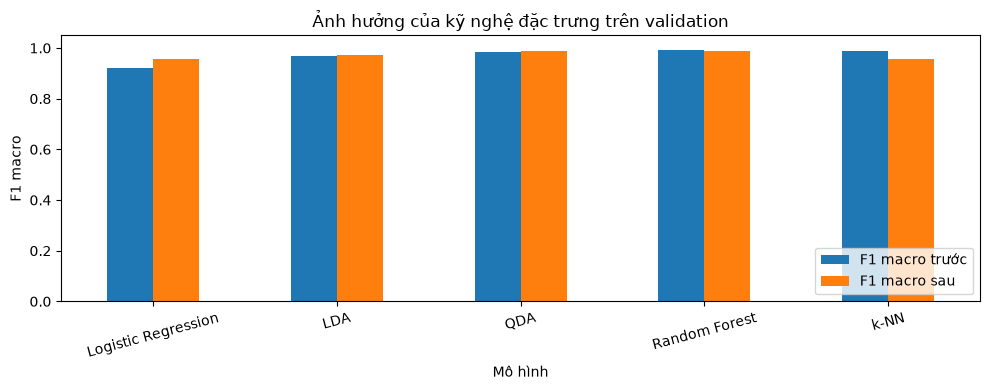

**Logistic Regression** có mức tăng F1 macro lớn nhất, **3.20 điểm phần trăm**. Mức tăng được đo trên một tập validation. Kiểm định chéo phía dưới đánh giá các cấu hình có kỹ nghệ đặc trưng.

In [3]:
scores = feature_comparison.set_index("Mô hình")[["F1 macro trước", "F1 macro sau"]]
ax = scores.plot.bar(figsize=(10, 4), rot=15, ylim=(0, 1.05))
ax.set(ylabel="F1 macro", title="Ảnh hưởng của kỹ nghệ đặc trưng trên validation")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

largest_gain = feature_comparison.loc[feature_comparison["Δ F1 (điểm %)"].idxmax()]
display(Markdown(
    f"**{largest_gain['Mô hình']}** có mức tăng F1 macro lớn nhất, "
    f"**{largest_gain['Δ F1 (điểm %)']:.2f} điểm phần trăm**. "
    "Mức tăng được đo trên một tập validation. Kiểm định chéo phía dưới đánh giá các cấu hình có kỹ nghệ đặc trưng."
))


## 3. Kết quả kiểm định chéo và tuning

tune_models.py dùng cùng 5 fold StratifiedKFold với shuffle=True và random_state=42.
GridSearchCV được dùng cho Logistic Regression, LDA, QDA và k-NN. Random Forest dùng RandomizedSearchCV với 12 ứng viên.
Tiêu chí tối ưu là F1 macro. Toàn bộ pipeline được fit riêng trong từng fold.

Các nhóm siêu tham số được tìm gồm C của Logistic Regression, solver/shrinkage của LDA, reg_param của QDA, số láng giềng/trọng số/khoảng cách của k-NN và các tham số cấu trúc cây của Random Forest.
Bảng sau đọc kết quả đã chạy từ results/cv_tuning_summary.csv.

Trong lượt so sánh dùng cấu hình mặc định hiện tại, Random Forest giảm khoảng 0,31 điểm phần trăm F1 macro và k-NN giảm khoảng 3,03 điểm phần trăm sau khi thêm đặc trưng. Kỹ nghệ đặc trưng cần được kiểm chứng cho từng thuật toán. Với k-NN, thêm chiều dữ liệu làm thay đổi khoảng cách giữa các mẫu. Kết quả tuning bên dưới dùng bộ đặc trưng mở rộng.


In [4]:
cv = pd.read_csv(ROOT / "results" / "cv_tuning_summary.csv")
cv["model"] = cv["model"].replace({"Random Forest (RandomizedSearch)": "Random Forest"})
cv = cv.sort_values("mean_cv_f1_macro", ascending=False, kind="stable").reset_index(drop=True)
assert cv["model"].nunique() == len(feature_comparison) == len(cv)
display(cv[["model", "search_method", "candidates_tested",
            "mean_cv_f1_macro", "std_cv_f1_macro"]].round(6))
for row in cv.itertuples(index=False):
    display(Markdown("**" + row.model + "**\n\n" + chr(96) * 3 + "json\n" + json.dumps(json.loads(row.best_params), indent=2) + "\n" + chr(96) * 3))
winner = cv.iloc[0]["model"]
display(Markdown(
    f"**Mô hình được CV chọn là {winner}**, có F1 macro trung bình "
    f"**{cv.iloc[0]['mean_cv_f1_macro']:.2%}**, độ lệch chuẩn "
    f"**{100 * cv.iloc[0]['std_cv_f1_macro']:.2f} điểm phần trăm**. "
    "Độ lệch chuẩn biểu thị dao động giữa các fold."
))


,model,search_method,candidates_tested,mean_cv_f1_macro,std_cv_f1_macro
0,Random Forest,random,12,0.995177,0.002008
1,QDA,grid,6,0.990899,0.003262
2,Logistic Regression,grid,5,0.980629,0.006080
3,k-NN,grid,30,0.970159,0.004640
4,LDA,grid,6,0.966677,0.005308


**Random Forest**

```json
{
  "classifier__max_depth": 25,
  "classifier__max_features": "sqrt",
  "classifier__min_samples_leaf": 1,
  "classifier__min_samples_split": 6,
  "classifier__n_estimators": 158
}
```

**QDA**

```json
{
  "classifier__reg_param": 0.01
}
```

**Logistic Regression**

```json
{
  "classifier__C": 50.0
}
```

**k-NN**

```json
{
  "classifier__metric": "manhattan",
  "classifier__n_neighbors": 5,
  "classifier__weights": "distance"
}
```

**LDA**

```json
{
  "classifier__shrinkage": 0.01,
  "classifier__solver": "lsqr"
}
```

**Mô hình được CV chọn là Random Forest**, có F1 macro trung bình **99.52%**, độ lệch chuẩn **0.20 điểm phần trăm**. Độ lệch chuẩn biểu thị dao động giữa các fold.

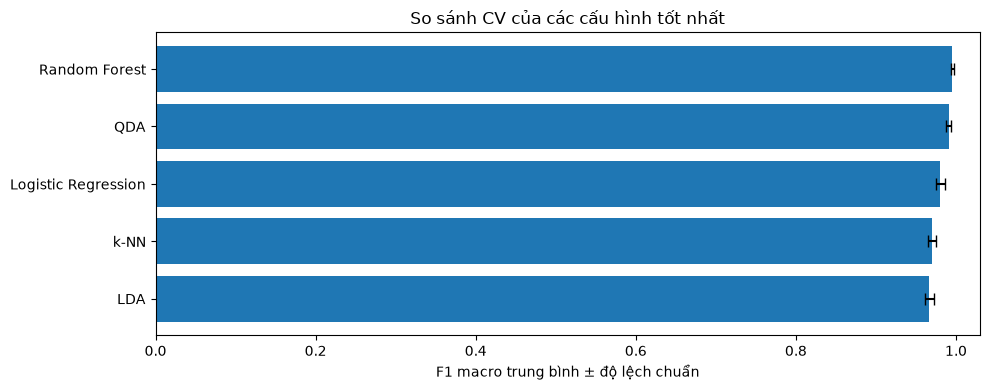

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(cv["model"][::-1], cv["mean_cv_f1_macro"][::-1],
        xerr=cv["std_cv_f1_macro"][::-1], capsize=4)
ax.set(xlim=(0, 1.03), xlabel="F1 macro trung bình ± độ lệch chuẩn",
       title="So sánh CV của các cấu hình tốt nhất")
plt.tight_layout()
plt.show()


## 4. Đánh giá cuối và kiểm tra pipeline dùng cho demo

Bảng test chứa các chỉ số của năm cấu hình đã chốt, được refit trên tập phát triển.
ROC-AUC dùng xác suất dự đoán, tính one-vs-rest rồi lấy trung bình macro cho 22 lớp.

Ô dưới đối chiếu tham số của các dòng kết quả với CSV tuning, sau đó nạp best_tuned_model.joblib và kiểm tra lại các chỉ số của mô hình được chọn.


In [6]:
test_metrics = pd.read_csv(ROOT / "results" / "final_test_metrics.csv")
assert set(test_metrics["model"]) == set(cv["model"])
for row in test_metrics.itertuples(index=False):
    cv_params = cv.loc[cv["model"] == row.model, "best_params"].item()
    assert json.loads(row.best_params) == json.loads(cv_params)

selected = load_best_model()
assert selected.selected_model_name_ == winner
for key, value in json.loads(cv.iloc[0]["best_params"]).items():
    assert selected.get_params()[key] == value
test_predictions = selected.predict(X_test)
test_probabilities = selected.predict_proba(X_test)
checked_metrics = compute_metrics(y_test, test_predictions, test_probabilities, selected.classes_)
saved_row = test_metrics.set_index("model").loc[winner]
for key, value in checked_metrics.items():
    np.testing.assert_allclose(value, saved_row[key])

metric_columns = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc_ovr_macro"]
display(test_metrics[["model", *metric_columns]].round(6))
print("Đã xác nhận tham số và điểm test của pipeline dùng chung với demo.")


Đã xác nhận tham số và điểm test của pipeline dùng chung với demo.


,model,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro
0,Random Forest,0.996970,0.997159,0.996970,0.996966,1.000000
1,QDA,0.990909,0.991811,0.990909,0.990879,1.000000
2,Logistic Regression,0.987879,0.988231,0.987879,0.987865,0.999942
3,k-NN,0.966667,0.968093,0.966667,0.966026,0.996652
4,LDA,0.966667,0.968850,0.966667,0.966689,0.999750


Random Forest đạt Accuracy và F1 macro xấp xỉ 99,70%. QDA đạt F1 macro 99,09%, Logistic Regression đạt 98,79%, LDA đạt 96,67% và k-NN đạt 96,60%.
ROC-AUC của Random Forest và QDA đạt 1,0 trên tập này. AUC đánh giá thứ hạng xác suất theo từng lớp, còn nhãn dự đoán cuối được chọn bằng xác suất lớn nhất giữa các lớp.


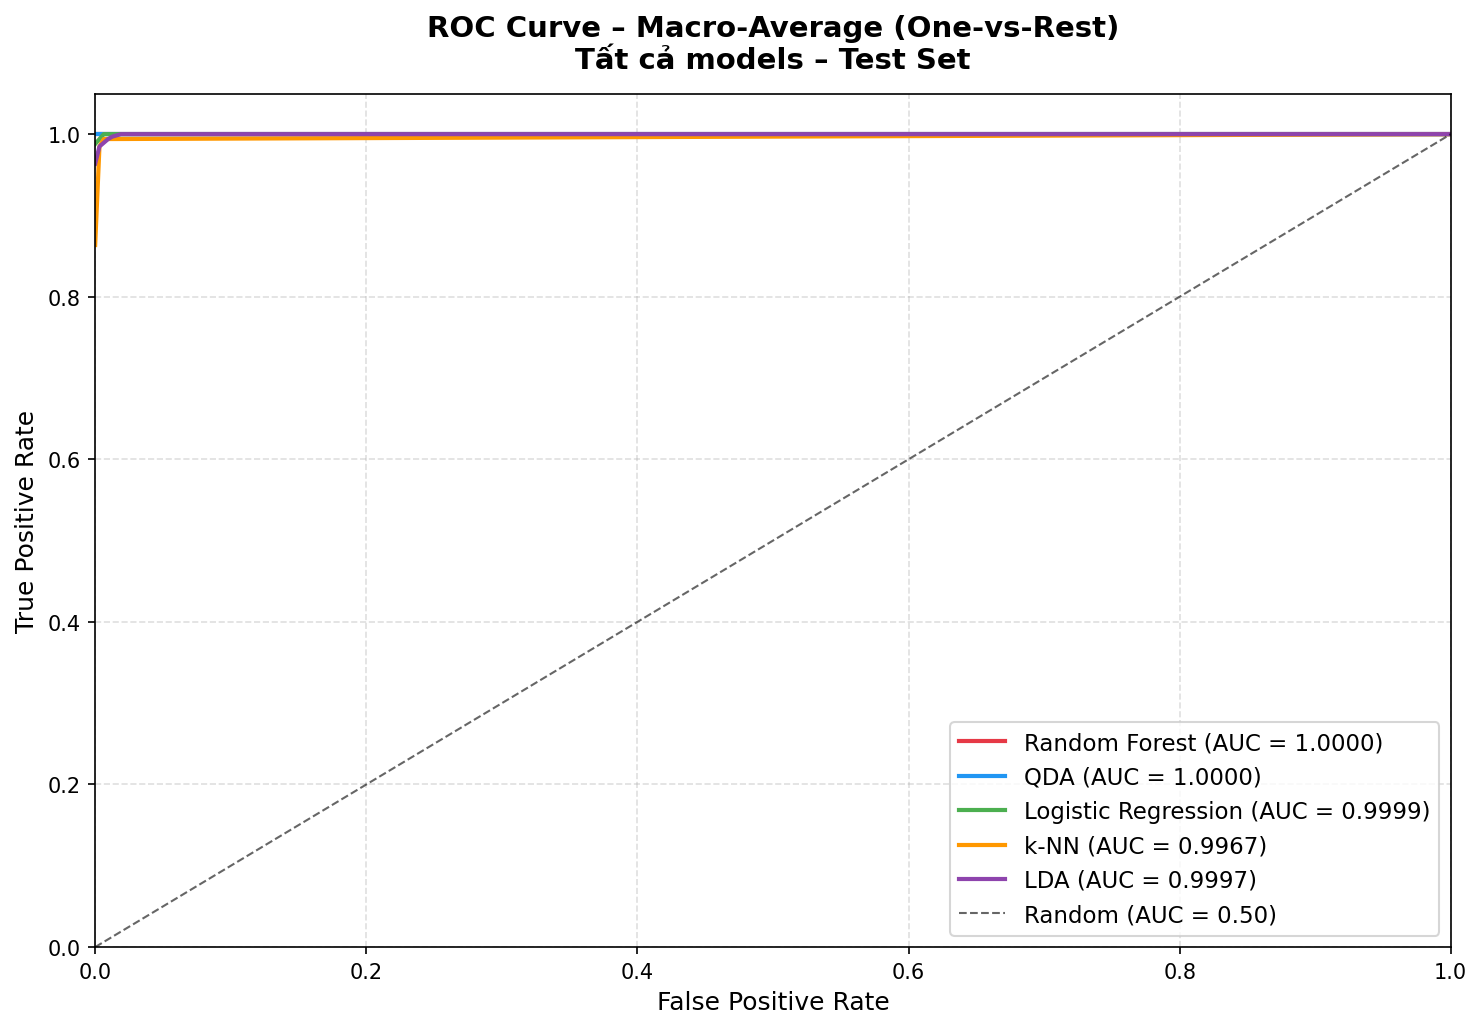

In [7]:
display(Image(filename=str(ROOT / "figures" / "roc_curve_all_models.png"), width=900))


## 5. Ma trận nhầm lẫn và nhận xét lỗi

Trong ma trận, hàng là nhãn thực và cột là nhãn dự đoán. Bảng cặp lỗi phía dưới ghi chiều nhầm rõ ràng cho từng mô hình.


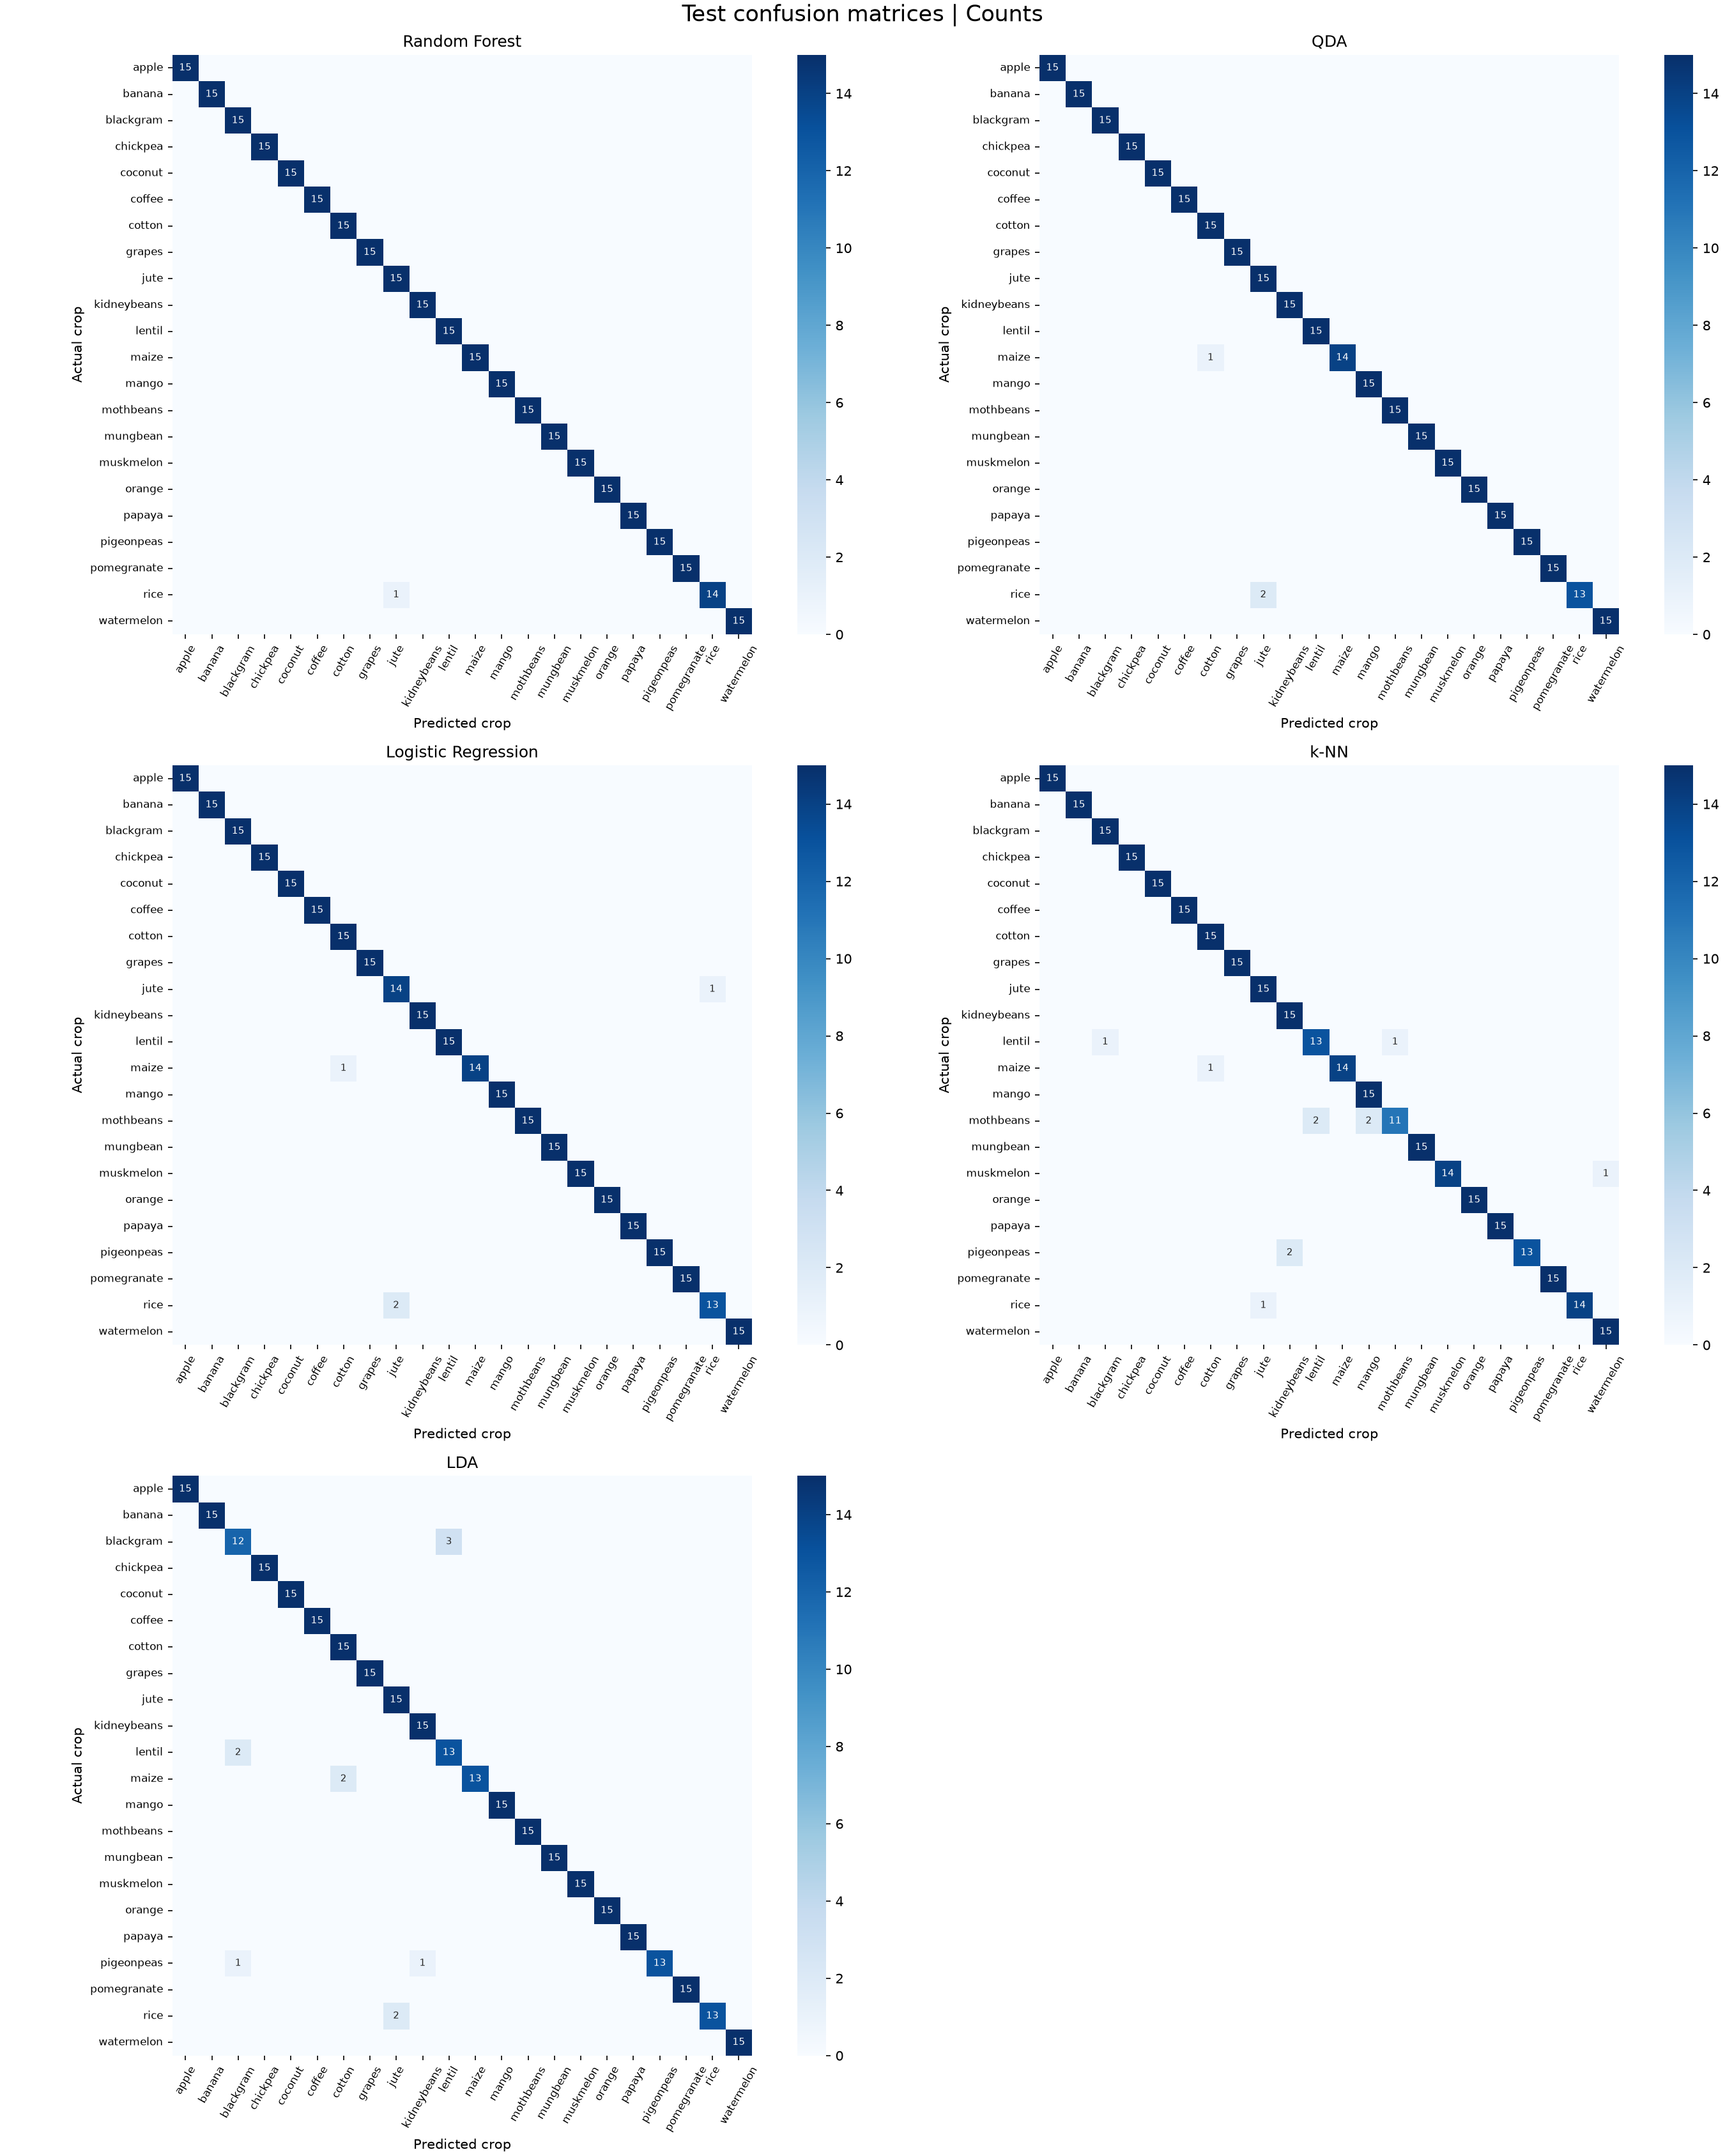

,model,actual_crop,predicted_crop,count
0,LDA,blackgram,lentil,3
1,LDA,lentil,blackgram,2
2,LDA,maize,cotton,2
3,LDA,rice,jute,2
4,Logistic Regression,rice,jute,2
5,QDA,rice,jute,2
6,k-NN,mothbeans,lentil,2
7,k-NN,mothbeans,mango,2
8,k-NN,pigeonpeas,kidneybeans,2
9,LDA,pigeonpeas,blackgram,1


In [8]:
display(Image(filename=str(ROOT / "figures" / "final_confusion_matrices.png"), width=1100))
confusion_pairs = pd.read_csv(ROOT / "results" / "final_confusion_pairs.csv")
display(confusion_pairs)
for model_name in test_metrics["model"]:
    error_count = confusion_pairs.loc[confusion_pairs["model"] == model_name, "count"].sum()
    accuracy = test_metrics.loc[test_metrics["model"] == model_name, "accuracy"].item()
    np.testing.assert_allclose(error_count, len(y_test) * (1 - accuracy), atol=1e-10)


In [9]:
wrong = test_predictions != y_test.to_numpy()
error_samples = X_test.loc[wrong].copy()
error_samples.insert(0, "Dòng trong X_test (bắt đầu từ 0)", X_test.index[wrong])
error_samples["Thực tế"] = y_test.to_numpy()[wrong]
error_samples["Dự đoán"] = test_predictions[wrong]
error_samples["Xác suất lớp được chọn"] = test_probabilities[wrong].max(axis=1)
display(error_samples)
correct = int((~wrong).sum())
display(Markdown(f"**{winner} dự đoán đúng {correct}/{len(y_test)} mẫu.**"))


,Dòng trong X_test (bắt đầu từ 0),N,P,K,temperature,humidity,ph,rainfall,Thực tế,Dự đoán,Xác suất lớp được chọn
208,208,91,35,38,24.897282,80.525861,6.134287,183.679321,rice,jute,0.633145


**Random Forest dự đoán đúng 329/330 mẫu.**

Random Forest có một lỗi rice → jute (lúa → đay). Cặp này cũng xuất hiện ở bốn mô hình còn lại. Maize → cotton (ngô → bông) xuất hiện ở QDA, Logistic Regression, k-NN và LDA.

LDA nhầm blackgram ↔ lentil tổng cộng 5 mẫu theo hai chiều. k-NN nhầm mothbeans thành lentil và mango, mỗi chiều nhầm có 2 mẫu.

Các lỗi lặp lại gợi ý cần xem xét độ chồng lấn đặc trưng giữa những lớp liên quan. Ma trận nhầm lẫn và điểm importance toàn cục cung cấp căn cứ để chọn các mẫu cần kiểm tra, còn nguyên nhân của từng lỗi cần phân tích thêm ở cấp mẫu.


## 6. Giải thích bằng permutation importance

Dữ liệu đọc từ results/final_permutation_importance.csv. validation_reference là pipeline mặc định fit trên train và đo trên validation. test_tuned là pipeline đã chốt và refit trên tập phát triển, đo trên test.

Mỗi cột gốc được xáo trộn 10 lần. Khi N, P, K hoặc pH thay đổi, pipeline tính lại các đặc trưng dẫn xuất.
Mức giảm F1 macro vì thế phản ánh ảnh hưởng của đầu vào gốc và những đặc trưng phụ thuộc vào nó. Tương quan giữa các cột có thể ảnh hưởng đến thứ hạng importance.


,feature,mean_f1_drop,std_f1_drop,source,model
0,N,0.34341,0.01586,validation_reference,Random Forest
1,K,0.26585,0.03509,validation_reference,Random Forest
2,humidity,0.23362,0.01678,validation_reference,Random Forest
3,P,0.17567,0.01907,validation_reference,Random Forest
4,rainfall,0.17522,0.01158,validation_reference,Random Forest
5,ph,0.01079,0.00525,validation_reference,Random Forest
6,temperature,0.00712,0.00411,validation_reference,Random Forest
7,N,0.33042,0.01655,test_tuned,Random Forest
8,K,0.29125,0.01575,test_tuned,Random Forest
9,humidity,0.28615,0.01245,test_tuned,Random Forest


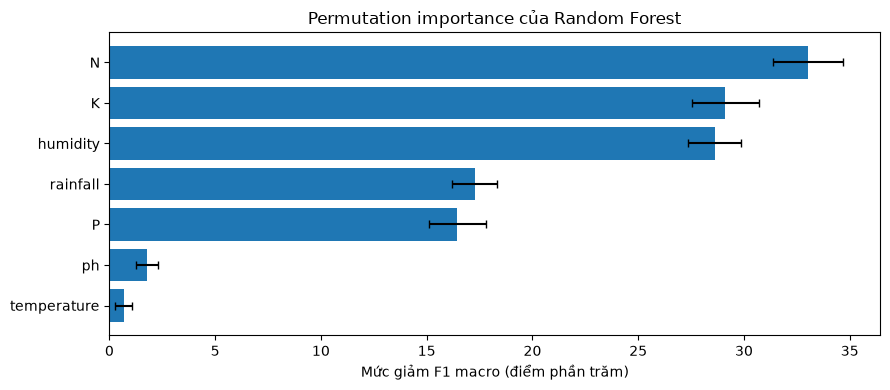

In [10]:
importance = pd.read_csv(ROOT / "results" / "final_permutation_importance.csv")
display(importance.round(5))
final_importance = importance.query("source == 'test_tuned' and model == @winner").sort_values("mean_f1_drop")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(final_importance["feature"], 100 * final_importance["mean_f1_drop"],
        xerr=100 * final_importance["std_f1_drop"], capsize=3)
ax.set(xlabel="Mức giảm F1 macro (điểm phần trăm)", title=f"Permutation importance của {winner}")
plt.tight_layout()
plt.show()


Ở pipeline Random Forest đã tuning, xáo trộn N, K và độ ẩm làm F1 macro giảm nhiều nhất, lần lượt khoảng 33,04, 29,13 và 28,61 điểm phần trăm. Đây cũng là ba đầu vào đứng đầu ở phép đo validation tham chiếu.

Kết quả cho thấy mô hình phụ thuộc mạnh vào dinh dưỡng đất và độ ẩm trên bộ dữ liệu này. Khoảng cách điểm giữa các mô hình cần được xem cùng kết quả CV và số mẫu test để đánh giá mức cải thiện.


## 7. Kiểm tra suy luận và cách tái tạo

Mẫu suy luận dưới đây lấy từ tập test để kiểm tra luồng dự đoán đơn lẻ và batch có cho cùng nhãn. Chỉ số đánh giá của toàn bộ tập đã được tính ở phần 4.


In [11]:
from predict import predict_crop

sample = X_test.iloc[0].to_dict()
demo_result = predict_crop(sample)[0]
assert demo_result["prediction"] == test_predictions[0]
display(pd.DataFrame([{"Nhãn thật": y_test.iloc[0], **demo_result}]))
print("Pipeline:", BEST_MODEL_PATH.name)
print("Các bước:", list(selected.named_steps))


[Model] Đang load model từ: D:\ML\wsplant\models\best_tuned_model.joblib
[Model] Load thành công! ✅
Pipeline: best_tuned_model.joblib
Các bước: ['features', 'preprocess', 'classifier']


,Nhãn thật,prediction,confidence,top3
0,coffee,coffee,0.99783,"[(coffee, 0.99783), (jute, 0.001266), (mango, ..."


Để tái tạo từ thư mục gốc, chạy theo thứ tự:

1. python src/preprocessing.py
2. python src/tune_models.py
3. python src/error_analysis.py
4. python src/predict.py

Sau đó mở notebook này và chạy Run All. Tuning và đánh giá chuyên sâu được thực hiện bằng các script trên để cập nhật CSV, biểu đồ và mô hình dùng chung. Notebook đọc lại những đầu ra đó, chạy so sánh đặc trưng và kiểm tra các kết quả của pipeline được lưu.

Phép kiểm tra tham số và điểm test giúp phát hiện các tệp kết quả khác phiên bản. Khi thay đổi pipeline hoặc không gian tìm kiếm, cần tái tạo các đầu ra bằng cùng một lượt thực nghiệm trước khi báo cáo.
